# Phase 2 — Visualisation & Key Inferences
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Dataset:** Power Consumption of Tetouan City (cleaned output of Phase 1)

14 unique plot types from the course. Each is chosen for the **attribute type** it fits and answers one question.

| # | Plot | Attribute type | Question |
|---|---|---|---|
| 07 | Histogram + KDE | continuous | shape, skew, modality of each variable |
| 08 | Box plot | numeric × category | weekday / weekend / holiday demand per zone |
| 09 | Violin | numeric × category | load density by part of day; Ramadan effect |
| 10 | Line | time series | yearly trend and seasonality per zone |
| 11 | Stacked area | time series, part-to-whole | each zone's contribution over the day |
| 12 | Scatter | numeric × numeric | temperature vs load |
| 13 | Donut (pie) | part-to-whole | annual energy share per zone |
| 14 | Grouped bar | category × category | seasonal change per zone |
| 15 | Pareto | ranked contribution | which hours carry most energy |
| 16 | Radar | multivariate profile | zone "personalities" on 6 metrics |
| 17 | Heatmap | two time axes | when the peak occurs across the year |
| 18 | Treemap | hierarchy | season → zone energy |
| 19 | Dot plot | small summary (36 values) | monthly level per zone, exact values |
| 20 | Stem-and-leaf | small summary (52 values) | distribution of weekly load, values kept |

Phase 1 diagnostic plots (01–06) are separate and not counted here.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, squarify
from matplotlib.lines import Line2D
from src.common import *

set_style(); header()
df = pd.read_csv(OUTPUTS / 'clean_features.csv', parse_dates=['datetime', 'date'])
ZL = {'zone1': 'Zone 1', 'zone2': 'Zone 2', 'zone3': 'Zone 3'}           # display names
SEASONS = ['Winter', 'Spring', 'Summer', 'Autumn']
fmt_k = plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k')                 # 32000 -> 32k
print(df.shape)

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption
(52416, 48)


## 07 · Histogram + KDE — distribution of every numeric attribute

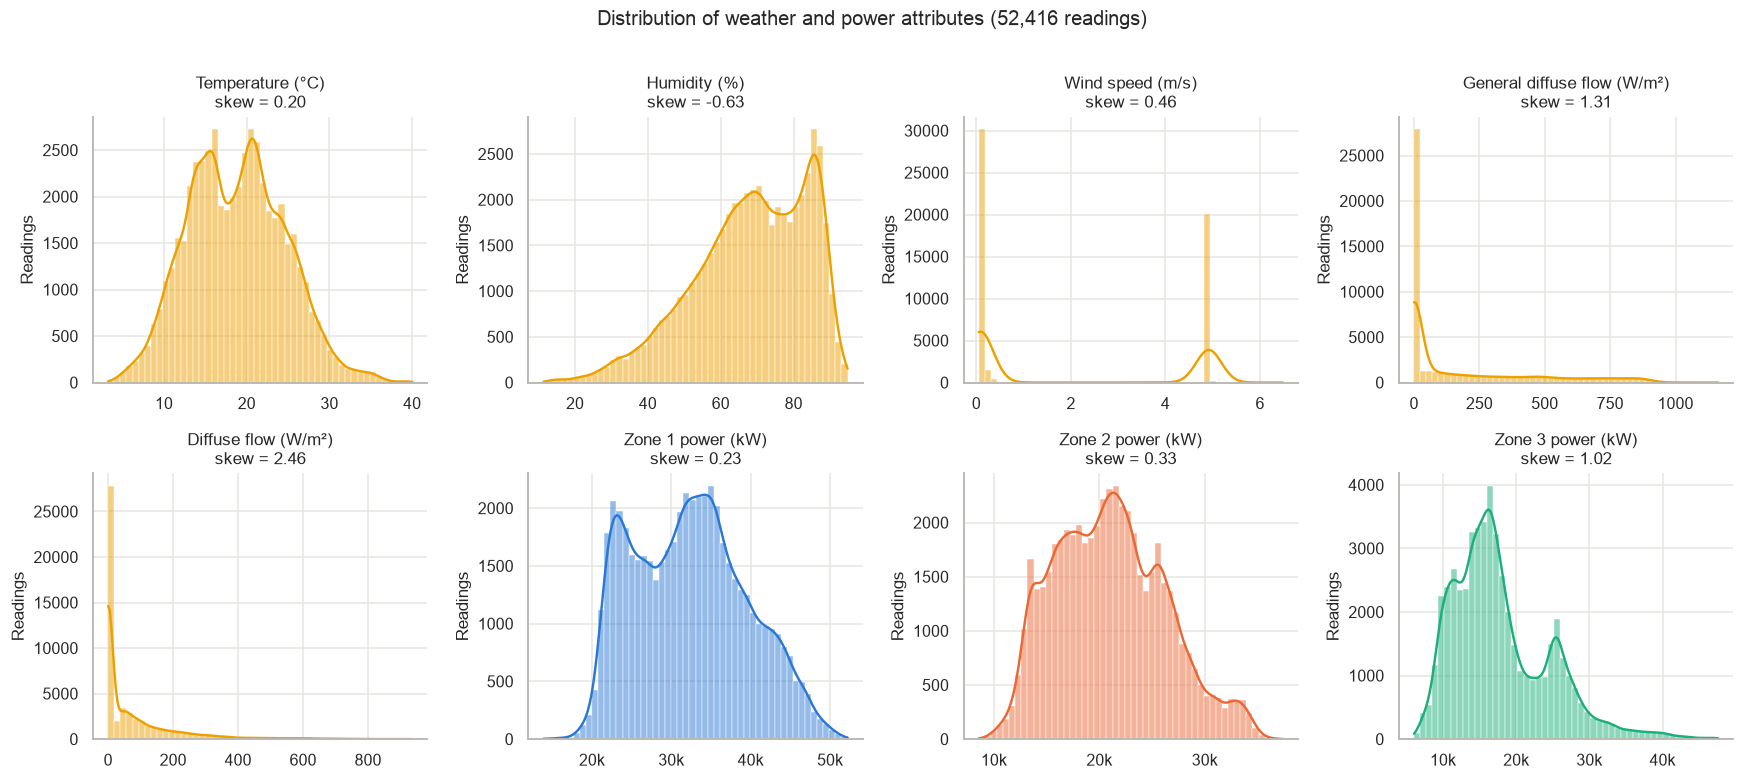

Skew: {'temperature': 0.2, 'humidity': -0.63, 'wind_speed': 0.46, 'gen_diffuse': 1.31, 'diffuse': 2.46, 'zone1': 0.23, 'zone2': 0.33, 'zone3': 1.02}
Share of night zeros (gen_diffuse == 0): 0.479
Wind: share < 0.5 m/s = 0.611 | share > 4 m/s = 0.386


In [2]:
cols = WEATHER + ZONES
labels = {'temperature': 'Temperature (°C)', 'humidity': 'Humidity (%)', 'wind_speed': 'Wind speed (m/s)',
          'gen_diffuse': 'General diffuse flow (W/m²)', 'diffuse': 'Diffuse flow (W/m²)',
          'zone1': 'Zone 1 power (kW)', 'zone2': 'Zone 2 power (kW)', 'zone3': 'Zone 3 power (kW)'}
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, cols):
    color = ZONE_COLORS.get(c, CAT[3])
    sns.histplot(df[c], bins=50, kde=True, color=color, edgecolor='white', linewidth=0.3, ax=ax)
    ax.set(title=f'{labels[c]}\nskew = {df[c].skew():.2f}', xlabel='', ylabel='Readings')
    if c in ZONES: ax.xaxis.set_major_formatter(fmt_k)
fig.suptitle('Distribution of weather and power attributes (52,416 readings)', y=1.01, fontsize=13)
fig.tight_layout(); save_fig('07_histogram_kde'); plt.show()

print('Skew:', df[cols].skew().round(2).to_dict())
print('Share of night zeros (gen_diffuse == 0):', round((df.gen_diffuse == 0).mean(), 3))
print('Wind: share < 0.5 m/s =', round((df.wind_speed < 0.5).mean(), 3), '| share > 4 m/s =', round((df.wind_speed > 4).mean(), 3))

**Inferences:**
- **Temperature** is near-symmetric (skew 0.20); **humidity** is left-skewed (−0.63): Tetouan is a humid coastal city, mostly 60–90 %.
- **Wind speed is bimodal**: 61 % of readings < 0.5 m/s and 39 % > 4 m/s, almost nothing in between → treat it as two regimes (Calm/Windy), not a continuous scale.
- **Irradiance**: 48 % exact zeros (night) plus a long right tail (skew 1.31 / 2.46) → justifies the log1p transform in Phase 1.
- **Zone 1** is bimodal (night vs day levels); **Zone 3** is right-skewed (1.02) because of its summer surge.

## 08 · Box plot — zone demand by day type

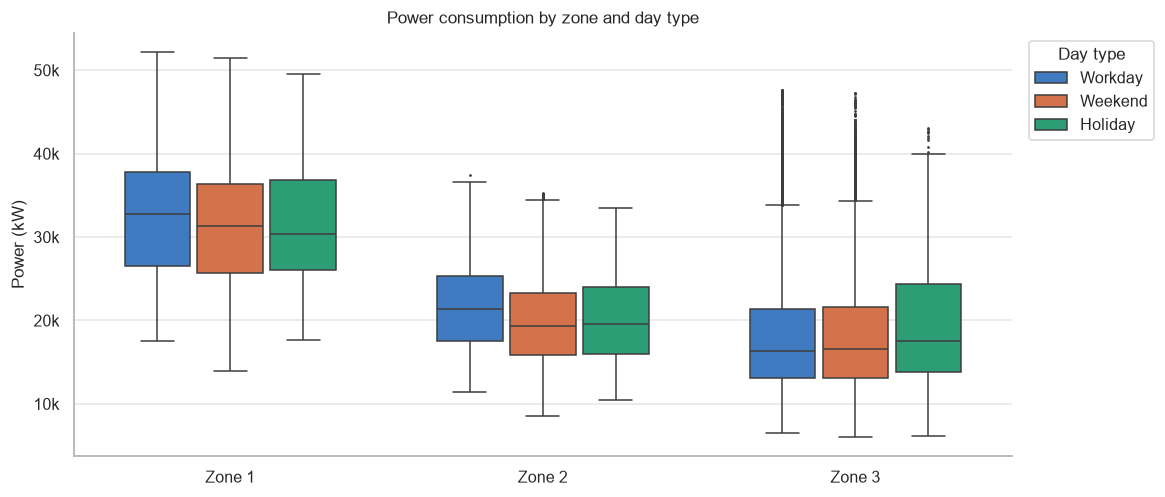

Medians (kW):
            zone1    zone2    zone3
day_type                           
Workday   32805.0  21365.0  16332.0
Weekend   31327.0  19338.0  16531.0
Holiday   30329.0  19616.0  17526.0

Drop vs Workday (%):
          zone1  zone2  zone3
day_type                     
Workday     0.0    0.0    0.0
Weekend    -4.5   -9.5    1.2
Holiday    -7.5   -8.2    7.3

Holiday months: {1: 2, 5: 1, 6: 2, 7: 1, 8: 3, 9: 3, 11: 2, 12: 1}


In [3]:
order = ['Workday', 'Weekend', 'Holiday']
long = df.melt(id_vars='day_type', value_vars=ZONES, var_name='zone', value_name='kW')
long['zone'] = long.zone.map(ZL)
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=long, x='zone', y='kW', hue='day_type', hue_order=order, palette=CAT[:3],
            fliersize=0.8, linewidth=1, width=0.7, gap=0.1, ax=ax)
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='Power consumption by zone and day type', xlabel='', ylabel='Power (kW)')
ax.legend(title='Day type', loc='upper left', bbox_to_anchor=(1.01, 1))
save_fig('08_box_zone_by_daytype'); plt.show()

med = df.groupby('day_type')[ZONES].median().loc[order]
print('Medians (kW):'); print(med.round(0))
print('\nDrop vs Workday (%):'); print(((med / med.loc['Workday'] - 1) * 100).round(1))
print('\nHoliday months:', pd.Series(df[df.day_type == 'Holiday'].drop_duplicates('date').date.dt.month).value_counts().sort_index().to_dict())

**Inferences:**
- Weekend demand drops **4.5 %** in Zone 1 and **9.5 %** in Zone 2 (median vs workday) → Zone 2 behaves most like a commercial/office area.
- Zone 3 does **not** drop at weekends (+1.2 %), and is +7.3 % on holidays. This is seasonal, not holiday behaviour: 7 of the 15 holidays fall in Jul–Sep, Zone 3's peak season.
- Zone 3 has the most high-end outliers — the same summer readings flagged by IQR in Phase 1.

## 09 · Violin — city load by part of day, Ramadan vs same-season days
Control group = the rest of May–June (similar weather), so the difference isolates Ramadan, not season.

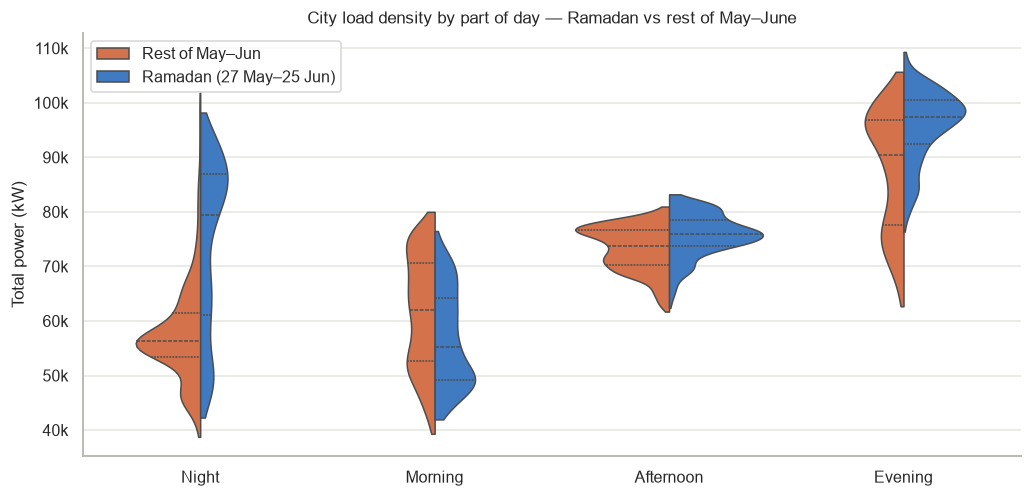

period       Ramadan (27 May–25 Jun)  Rest of May–Jun
part_of_day                                          
Night                        79486.0          56270.0
Morning                      55182.0          62095.0
Afternoon                    75983.0          73803.0
Evening                      97346.0          90475.0


In [4]:
window = df[df.month.isin([5, 6])].copy()
window['period'] = np.where(window.is_ramadan == 1, 'Ramadan (27 May–25 Jun)', 'Rest of May–Jun')
parts = ['Night', 'Morning', 'Afternoon', 'Evening']
fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=window, x='part_of_day', y='total_power', hue='period', order=parts, split=True,
               inner='quart', palette=[CAT[1], CAT[0]], linewidth=1, cut=0, ax=ax)
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='City load density by part of day — Ramadan vs rest of May–June', xlabel='', ylabel='Total power (kW)')
ax.legend(title='', loc='upper left')
save_fig('09_violin_ramadan_part_of_day'); plt.show()

print((window.groupby(['part_of_day', 'period']).total_power.median().unstack().loc[parts]).round(0))

**Inferences (medians, Ramadan vs rest of May–June):**
- **Night load +41 %** (79.5k vs 56.3k kW) — households awake for *suhoor*; the Ramadan night violin is shifted far upward.
- **Morning load −11 %** (55.2k vs 62.1k kW) — later starts and shorter working hours.
- Evening +8 % (97.3k vs 90.5k kW, *iftar* and night activity); afternoon nearly unchanged.
- Ramadan **moves** demand from morning to night rather than adding a uniform increase → `is_ramadan` is a valid ARM item and DIANA day label.

## 10 · Line chart — daily mean consumption over 2017

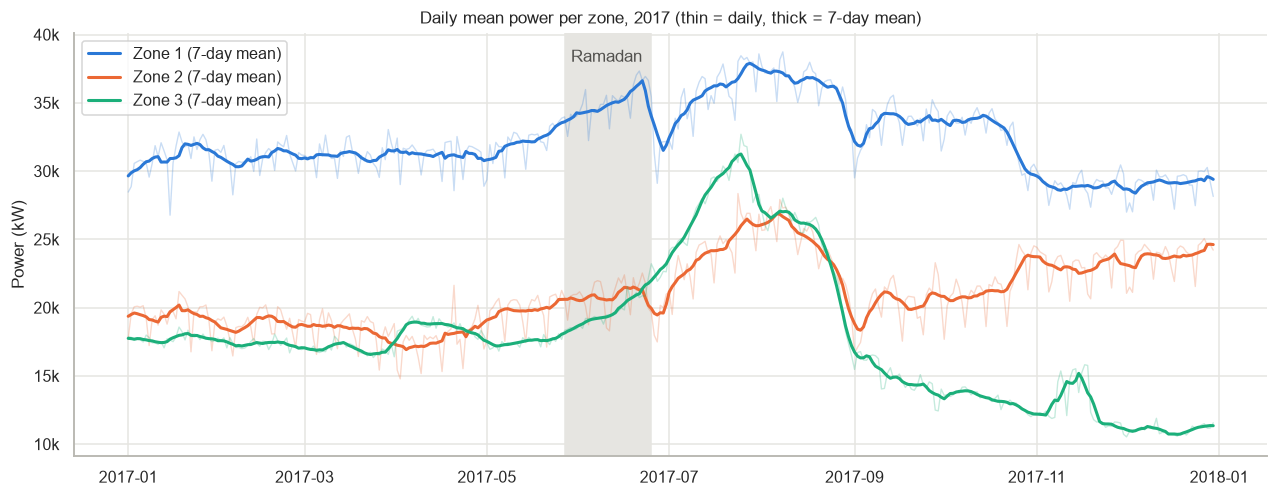

Monthly mean (kW):
month       1        2        3        4        5        6        7        8   \
zone1  31032.0  30986.0  31155.0  31174.0  32397.0  34606.0  35832.0  36436.0   
zone2  19394.0  18788.0  18458.0  17634.0  19977.0  20671.0  24148.0  24656.0   
zone3  17746.0  17335.0  16948.0  18593.0  17622.0  20431.0  28194.0  24649.0   

month       9        10       11       12  
zone1  33397.0  32828.0  29002.0  29024.0  
zone2  20180.0  21469.0  23240.0  23684.0  
zone3  14924.0  13264.0  12864.0  11045.0  

Peak month / min month ratio: {'zone1': 1.26, 'zone2': 1.4, 'zone3': 2.55}
Peak month: {'zone1': 8, 'zone2': 8, 'zone3': 7} | min month: {'zone1': 11, 'zone2': 4, 'zone3': 12}


In [5]:
daily = df.groupby('date')[ZONES].mean()
roll = daily.rolling(7, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(14, 5))
for z in ZONES:
    ax.plot(daily.index, daily[z], color=ZONE_COLORS[z], alpha=0.25, lw=0.9)
    ax.plot(roll.index, roll[z], color=ZONE_COLORS[z], lw=2, label=f'{ZL[z]} (7-day mean)')
ax.axvspan(pd.Timestamp('2017-05-27'), pd.Timestamp('2017-06-25'), color='#e6e5e1', zorder=0)
ax.text(pd.Timestamp('2017-06-10'), ax.get_ylim()[1]*0.97, 'Ramadan', ha='center', va='top', color='#52514e')
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='Daily mean power per zone, 2017 (thin = daily, thick = 7-day mean)', xlabel='', ylabel='Power (kW)')
ax.legend(loc='upper left')
save_fig('10_line_daily_trend'); plt.show()

mon = df.groupby('month')[ZONES].mean()
print('Monthly mean (kW):'); print(mon.round(0).T)
print('\nPeak month / min month ratio:', (mon.max() / mon.min()).round(2).to_dict())
print('Peak month:', mon.idxmax().to_dict(), '| min month:', mon.idxmin().to_dict())

**Inferences:**
- All zones peak in **July–August**; Zone 3 swings the most (peak/min month = **2.55×**, vs 1.26× Zone 1 and 1.40× Zone 2).
- After summer the zones **diverge**: Zone 3 falls to 11.0k kW in December, while Zone 2 rises to 23.7k kW (Oct–Dec) → different customer mix per zone.
- Sharp one-week dips at the end of June and around 1 September match **Eid al-Fitr** and **Eid al-Adha**.
- Load climbs through Ramadan (shaded) and drops right after it.

## 11 · Stacked area — average 24-hour profile, zone contributions

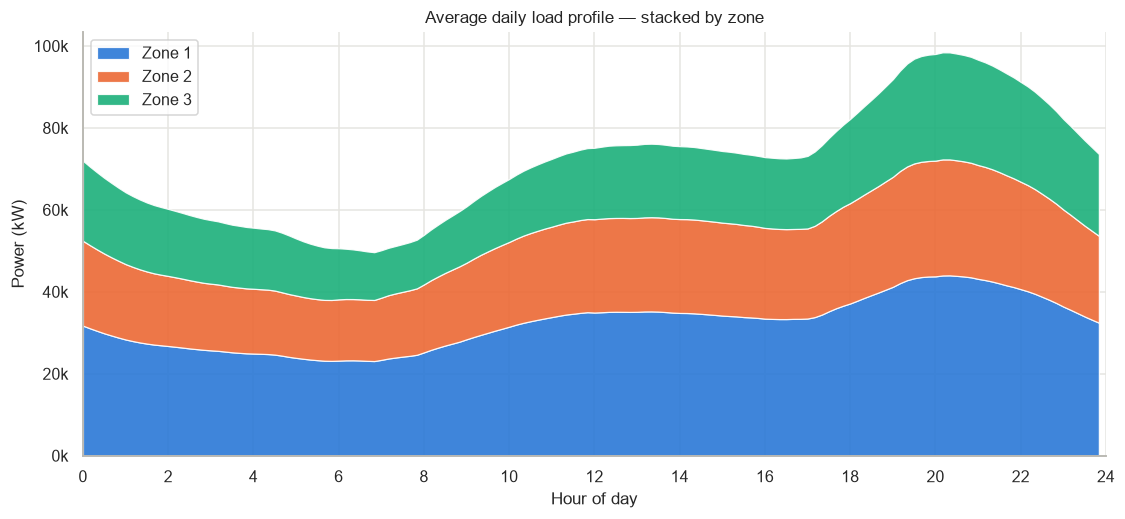

Peak at 20.17 h = 98,449 kW | trough at 6.83 h = 49,667 kW | ratio 1.98
Zone share at trough: {'zone1': 0.465, 'zone2': 0.3, 'zone3': 0.235}
Zone share at peak  : {'zone1': 0.447, 'zone2': 0.288, 'zone3': 0.265}
Peak-to-trough ratio per zone: {'zone1': 1.91, 'zone2': 1.91, 'zone3': 2.26}


In [6]:
df['tod'] = df.datetime.dt.hour + df.datetime.dt.minute / 60
prof = df.groupby('tod')[ZONES].mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(prof.index, *[prof[z] for z in ZONES], labels=[ZL[z] for z in ZONES],
             colors=[ZONE_COLORS[z] for z in ZONES], alpha=0.9, edgecolor='white', linewidth=0.8)
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='Average daily load profile — stacked by zone', xlabel='Hour of day', ylabel='Power (kW)',
       xlim=(0, 24), xticks=range(0, 25, 2))
ax.legend(loc='upper left')
save_fig('11_stacked_area_daily_profile'); plt.show()

tot = prof.sum(axis=1)
print(f'Peak at {tot.idxmax():.2f} h = {tot.max():,.0f} kW | trough at {tot.idxmin():.2f} h = {tot.min():,.0f} kW | ratio {tot.max()/tot.min():.2f}')
print('Zone share at trough:', (prof.loc[tot.idxmin()] / tot.min()).round(3).to_dict())
print('Zone share at peak  :', (prof.loc[tot.idxmax()] / tot.max()).round(3).to_dict())
print('Peak-to-trough ratio per zone:', (prof.max() / prof.min()).round(2).to_dict())

**Inferences:**
- City load bottoms out at **06:50 (49.7k kW)** and peaks at **20:10 (98.4k kW)** — a **2.0×** daily swing.
- The evening ramp (≈17:30–20:00) coincides with sunset and lighting, not with working hours.
- Zone 3's share grows from 23.5 % at the trough to 26.5 % at the peak; its own peak/trough ratio (2.26) is the largest → Zone 3 drives the evening peak.

## 12 · Scatter — temperature vs city load, coloured by hour

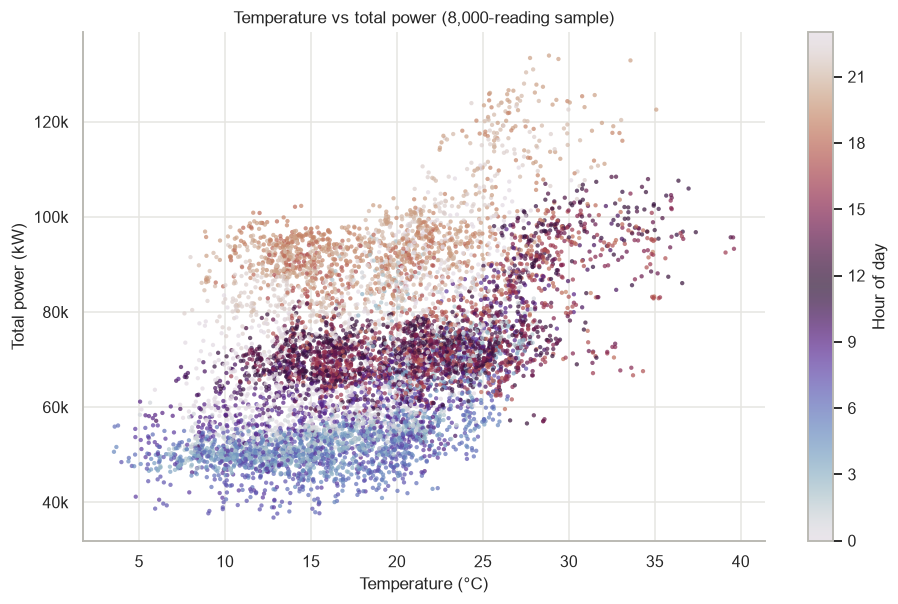

Overall r = 0.49 | mean within-hour r = 0.59 (min -0.03, max 0.77)
Readings > 30 °C: 1437 | their mean load 95,491 vs overall 71,224 kW


In [7]:
s = df.sample(8000, random_state=SEED)
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(s.temperature, s.total_power, c=s.hour, cmap='twilight', s=8, alpha=0.7, linewidths=0)
cb = fig.colorbar(sc, ax=ax, label='Hour of day', ticks=range(0, 24, 3))
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='Temperature vs total power (8,000-reading sample)', xlabel='Temperature (°C)', ylabel='Total power (kW)')
save_fig('12_scatter_temp_vs_load'); plt.show()

r_all = df.temperature.corr(df.total_power)
r_hour = df.groupby('hour').apply(lambda g: g.temperature.corr(g.total_power), include_groups=False)
print(f'Overall r = {r_all:.2f} | mean within-hour r = {r_hour.mean():.2f} (min {r_hour.min():.2f}, max {r_hour.max():.2f})')
hot = df[df.temperature > 30]
print(f'Readings > 30 °C: {len(hot)} | their mean load {hot.total_power.mean():,.0f} vs overall {df.total_power.mean():,.0f} kW')

**Inferences:**
- Overall correlation is moderate (**r = 0.49**), but **within the same hour** it averages **r = 0.59** (up to 0.77) → time of day hides the temperature effect; both are needed in KNN.
- Two horizontal bands: evening readings (warm colours) stay high even at 10–15 °C → the evening peak is lighting-driven, not weather-driven.
- Readings above 30 °C average **95.5k kW vs 71.2k kW** overall (+34 %) → cooling load on hot days.

## 13 · Donut (pie) — share of annual energy by zone

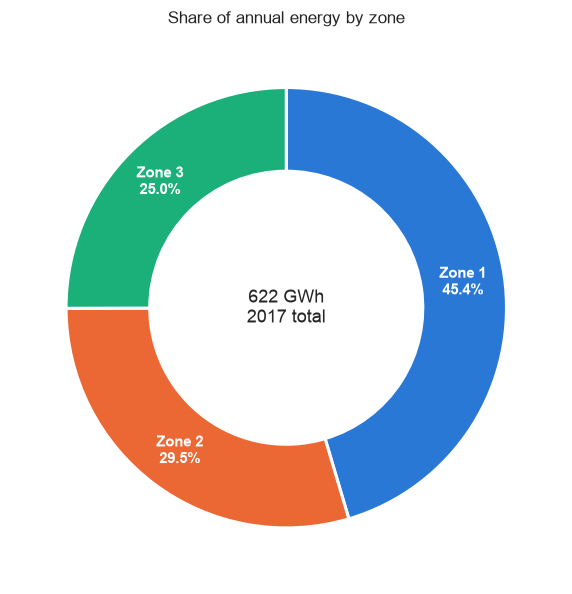

Energy (GWh): {'zone1': 282.6, 'zone2': 183.8, 'zone3': 155.8} | share: {'zone1': 0.454, 'zone2': 0.295, 'zone3': 0.25}


In [8]:
energy = df[ZONES].sum() / 6 / 1e6                     # kW x 10-min -> kWh -> GWh
fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, _ = ax.pie(energy, colors=[ZONE_COLORS[z] for z in ZONES], startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.38, edgecolor='white', linewidth=2))
for w, z in zip(wedges, ZONES):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    ax.text(0.81*np.cos(ang), 0.81*np.sin(ang), f'{ZL[z]}\n{energy[z]/energy.sum():.1%}', ha='center',
            va='center', color='white', fontsize=10, fontweight='bold')
ax.text(0, 0, f'{energy.sum():,.0f} GWh\n2017 total', ha='center', va='center', fontsize=12)
ax.set_title('Share of annual energy by zone')
save_fig('13_donut_energy_share'); plt.show()

print('Energy (GWh):', energy.round(1).to_dict(), '| share:', (energy / energy.sum()).round(3).to_dict())

**Inferences:**
- 2017 city consumption ≈ **622 GWh**.
- Zone 1 = **45.4 %** (283 GWh), Zone 2 = **29.5 %** (184 GWh), Zone 3 = **25.0 %** (156 GWh).
- Zone 1 alone is close to half of the city → most of the demand-management benefit lies there, but Zone 3 is where the volatility comes from (plots 10, 16).

## 14 · Grouped bar — mean load by season and zone

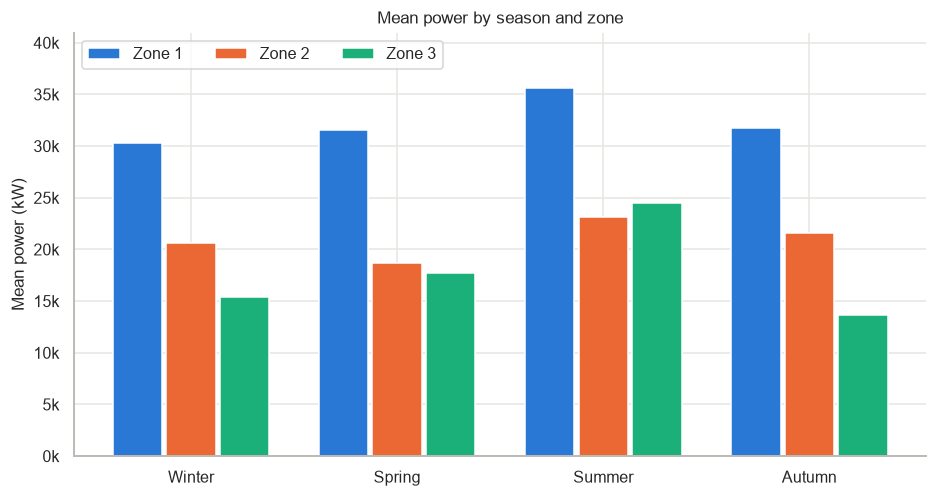

          zone1    zone2    zone3
season                           
Winter  30341.0  20649.0  15358.0
Spring  31580.0  18701.0  17712.0
Summer  35635.0  23185.0  24468.0
Autumn  31754.0  21628.0  13680.0

Summer vs Winter change (%): {'zone1': 17.5, 'zone2': 12.3, 'zone3': 59.3}


In [9]:
sea = df.groupby('season')[ZONES].mean().loc[SEASONS]
x = np.arange(len(SEASONS)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 5))
for i, z in enumerate(ZONES):
    bars = ax.bar(x + (i-1)*w, sea[z], width=w-0.02, color=ZONE_COLORS[z], label=ZL[z])
ax.set_xticks(x, SEASONS); ax.yaxis.set_major_formatter(fmt_k)
ax.set(title='Mean power by season and zone', ylabel='Mean power (kW)', ylim=(0, sea.max().max()*1.15))
ax.legend(loc='upper left', ncol=3)
save_fig('14_grouped_bar_season_zone'); plt.show()

print(sea.round(0))
print('\nSummer vs Winter change (%):', ((sea.loc['Summer'] / sea.loc['Winter'] - 1) * 100).round(1).to_dict())

**Inferences:**
- Summer vs winter: Zone 1 **+17.5 %**, Zone 2 **+12.3 %**, Zone 3 **+59.3 %**.
- Zone 3 is lowest in **autumn** (13.7k kW, even below winter) — its demand collapses once the summer season ends.
- Zone 3 overtakes Zone 2 only in summer → the zone ranking changes with season, so season is a useful ARM item.

## 15 · Pareto — energy contribution by hour of day

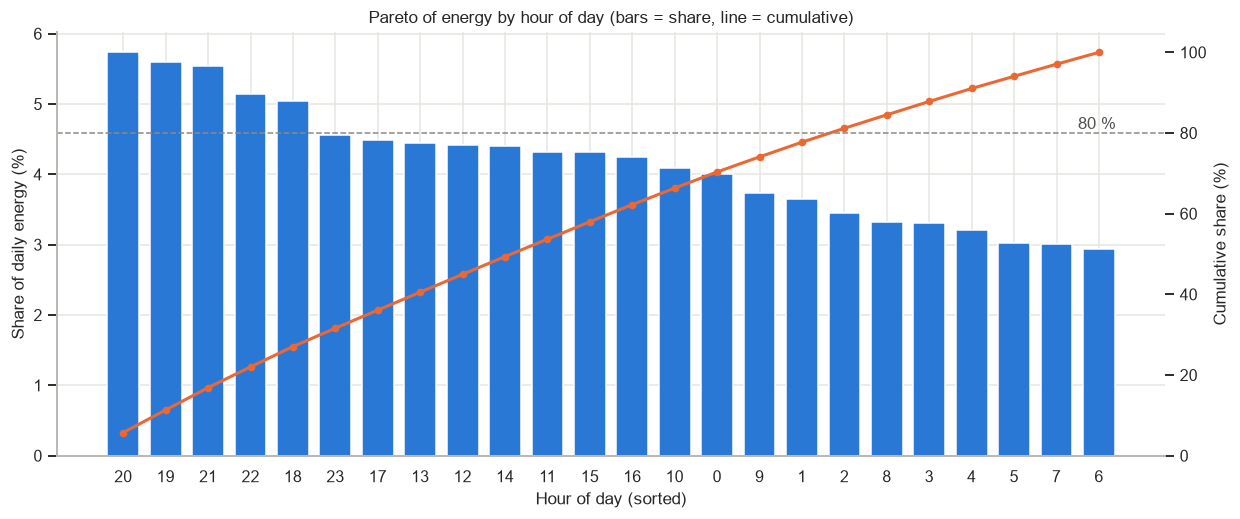

Hours to reach 50 %: 11 -> [11, 12, 13, 14, 17, 18, 19, 20, 21, 22, 23]
Hours to reach 80 %: 18 (uniform would need 19.2)
Top hour 20:00 = 5.74% | bottom hour 6:00 = 2.94%


In [10]:
by_hour = df.groupby('hour').total_power.sum().sort_values(ascending=False)
cum = by_hour.cumsum() / by_hour.sum() * 100
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(by_hour.index.astype(str), by_hour / by_hour.sum() * 100, color=CAT[0], width=0.75)
ax.set(title='Pareto of energy by hour of day (bars = share, line = cumulative)', xlabel='Hour of day (sorted)',
       ylabel='Share of daily energy (%)')
ax2 = ax.twinx()                                           # cumulative % shares the same 0-100 meaning
ax2.plot(by_hour.index.astype(str), cum, color=CAT[1], marker='o', ms=4, lw=2)
ax2.axhline(80, color='#8a8984', ls='--', lw=1); ax2.text(23.4, 81, '80 %', ha='right', color='#52514e')
ax2.set(ylim=(0, 105), ylabel='Cumulative share (%)'); ax2.grid(False)
save_fig('15_pareto_energy_by_hour'); plt.show()

n50, n80 = (cum < 50).sum() + 1, (cum < 80).sum() + 1
print(f'Hours to reach 50 %: {n50} -> {sorted(by_hour.index[:n50].tolist())}')
print(f'Hours to reach 80 %: {n80} (uniform would need {0.8*24:.1f})')
print(f'Top hour {by_hour.index[0]}:00 = {by_hour.iloc[0]/by_hour.sum():.2%} | bottom hour {by_hour.index[-1]}:00 = {by_hour.iloc[-1]/by_hour.sum():.2%}')

**Inferences:**
- The top 5 hours (**18:00–22:00**) carry ≈ **27 %** of daily energy; 20:00 alone carries 5.74 %, twice 06:00 (2.94 %).
- 11 hours reach 50 % and 18 hours reach 80 % (uniform = 19.2) → no 80/20 rule: the base load is large and spread out.
- Peak-shaving should target the **evening window**, which is where any tariff or storage effort pays off.

## 16 · Radar — zone profiles on six metrics
Each metric is scaled by its maximum across the three zones (outer ring = highest zone).

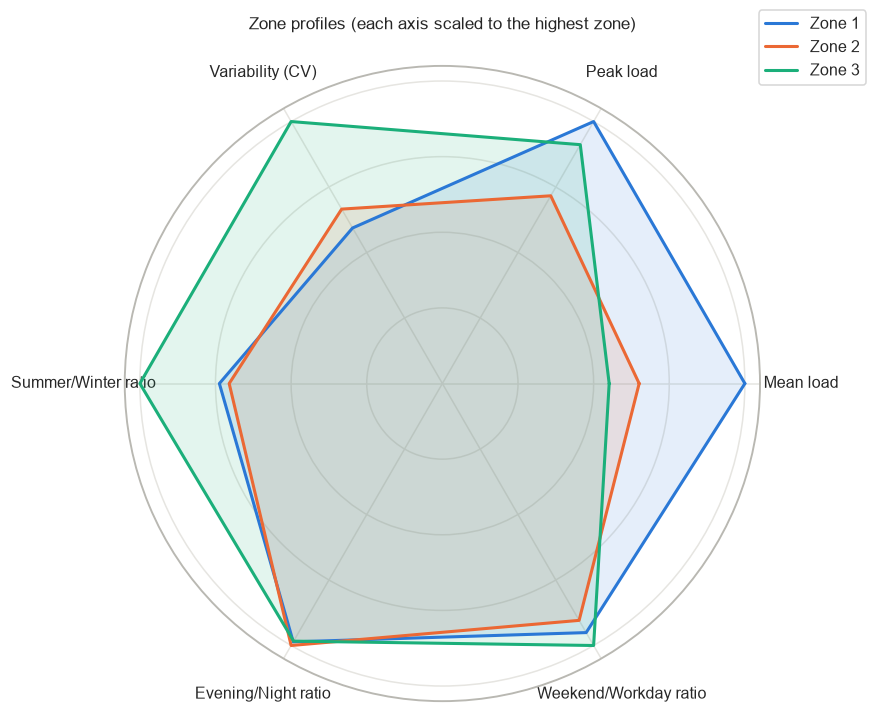

,Mean load,Peak load,Variability (CV),Summer/Winter ratio,Evening/Night ratio,Weekend/Workday ratio
zone1,32345.512,52204.395,0.220,1.175,1.779,0.963
zone2,21042.650,37408.861,0.247,1.123,1.804,0.915
zone3,17835.759,47598.326,0.371,1.593,1.774,1.012


In [11]:
hp = df.groupby('hour')[ZONES].mean()
metrics = pd.DataFrame({
    'Mean load': df[ZONES].mean(),
    'Peak load': df[ZONES].max(),
    'Variability (CV)': df[ZONES].std() / df[ZONES].mean(),
    'Summer/Winter ratio': sea.loc['Summer'] / sea.loc['Winter'],
    'Evening/Night ratio': hp.loc[20] / hp.loc[4],
    'Weekend/Workday ratio': df[df.is_weekend == 1][ZONES].mean() / df[df.day_type == 'Workday'][ZONES].mean(),
})
scaled = metrics / metrics.max()
ang = np.linspace(0, 2*np.pi, len(metrics.columns), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw=dict(polar=True))
for z in ZONES:
    v = scaled.loc[z].tolist(); v += v[:1]
    ax.plot(ang, v, color=ZONE_COLORS[z], lw=2, label=ZL[z]); ax.fill(ang, v, color=ZONE_COLORS[z], alpha=0.12)
ax.set_xticks(ang[:-1], metrics.columns); ax.set_yticks([0.25, 0.5, 0.75, 1.0], ['', '', '', ''])
ax.set_ylim(0, 1.05); ax.tick_params(axis='x', pad=14)
ax.set_title('Zone profiles (each axis scaled to the highest zone)', pad=24)
ax.legend(loc='upper right', bbox_to_anchor=(1.18, 1.1))
save_fig('16_radar_zone_profiles'); plt.show()
metrics.round(3)

**Inferences (raw values in the table above):**
- **Zone 1**: largest mean (32.3k) and peak (52.2k kW), lowest variability (CV 0.22) → large, steady base load.
- **Zone 3**: highest variability (CV 0.37) and summer/winter ratio (1.59) → seasonal, tourism-driven.
- **Zone 2**: lowest weekend/workday ratio (0.92) → most weekday-dependent.
- The evening/night ratio is ≈ 1.78–1.80 for all three → the evening peak is a **city-wide** pattern.

## 17 · Heatmap — mean city load by hour × month

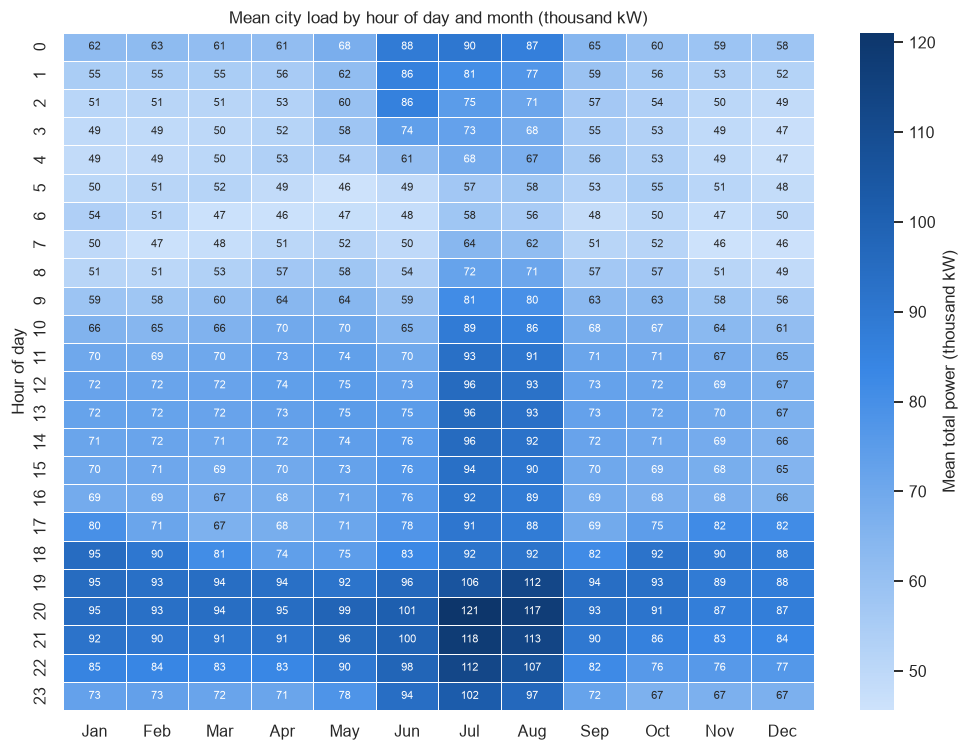

Peak hour per month: {1: 19, 2: 20, 3: 19, 4: 20, 5: 20, 6: 20, 7: 20, 8: 20, 9: 19, 10: 19, 11: 18, 12: 18}
Hottest cell: (np.int64(20), np.int64(7)) = 121,096 kW | coolest: (np.int64(5), np.int64(5)) = 45,643 kW
Jun vs May at 03h (kW): 73890 vs 58157


In [12]:
hm = df.pivot_table(index='hour', columns='month', values='total_power', aggfunc='mean')
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hm/1000, cmap='seq_blue', linewidths=0.4, linecolor='white', annot=True, fmt='.0f',
            annot_kws={'size': 7}, cbar_kws={'label': 'Mean total power (thousand kW)'}, ax=ax)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set(title='Mean city load by hour of day and month (thousand kW)', xlabel='', ylabel='Hour of day')
save_fig('17_heatmap_hour_month'); plt.show()

pk = hm.idxmax()
print('Peak hour per month:', pk.to_dict())
print(f'Hottest cell: {hm.stack().idxmax()} = {hm.max().max():,.0f} kW | coolest: {hm.stack().idxmin()} = {hm.min().min():,.0f} kW')
print('Jun vs May at 03h (kW):', round(hm.loc[3, 6]), 'vs', round(hm.loc[3, 5]))

**Inferences:**
- The daily peak hour **moves with sunset**: 18:00 in Nov–Dec, 19:00 in Jan/Mar/Sep/Oct, 20:00 from April to August → lighting drives the peak.
- Highest cell: **July 20:00 = 121k kW**; lowest: **May 05:00 = 45.6k kW** (2.65× apart).
- **June 00:00–03:00** reads 74–88k kW vs 58–68k kW in May — the Ramadan night block is clearly visible.
- July–August are high **all day**, not only in the evening → summer adds a daytime cooling load.

## 18 · Treemap — energy hierarchy: season → zone

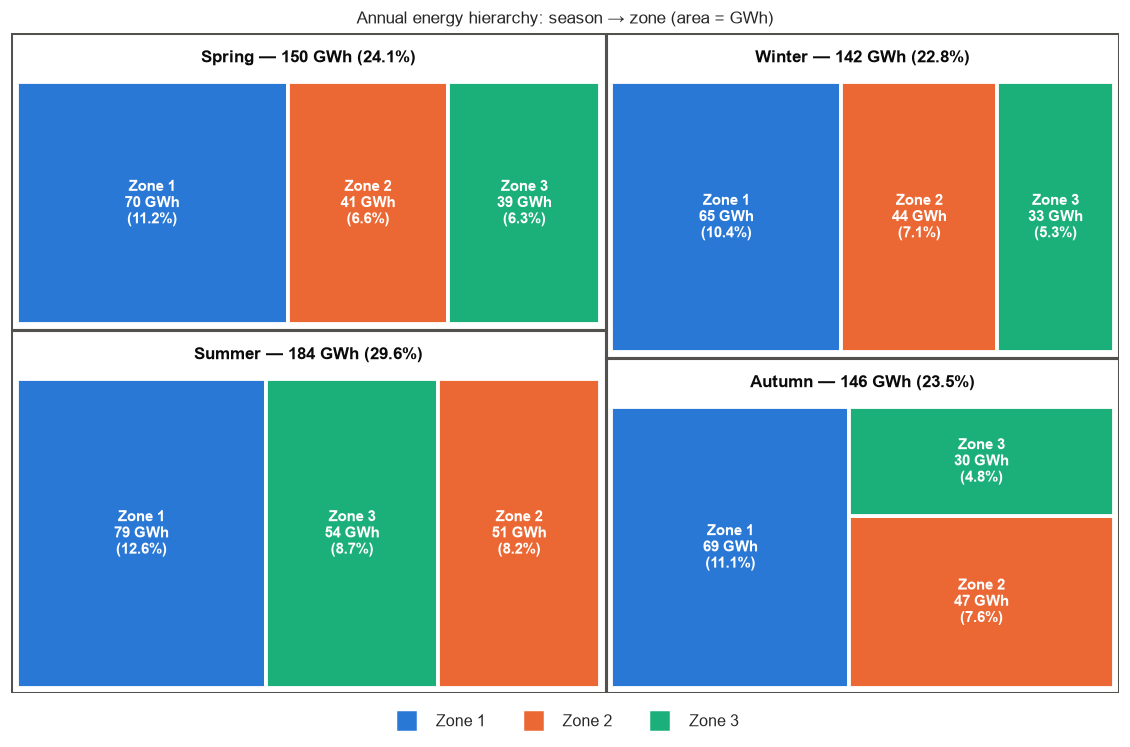

Season totals (GWh): {'Summer': 183.9, 'Spring': 150.1, 'Autumn': 146.5, 'Winter': 141.7}
season  zone    GWh  share
Summer zone1 78.683  0.126
Spring zone1 69.728  0.112
Autumn zone1 69.351  0.111
Winter zone1 64.808  0.104
Summer zone3 54.025  0.087
Summer zone2 51.193  0.082
Autumn zone2 47.236  0.076
Winter zone2 44.107  0.071
Spring zone2 41.292  0.066
Spring zone3 39.107  0.063
Winter zone3 32.805  0.053
Autumn zone3 29.876  0.048


In [13]:
from matplotlib.patches import Rectangle
tm = (df.groupby('season')[ZONES].sum() / 6 / 1e6).loc[SEASONS]
tm = tm.stack().rename('GWh').reset_index().rename(columns={'level_1': 'zone'})
tm['share'] = tm.GWh / tm.GWh.sum()
season_e = tm.groupby('season').GWh.sum().sort_values(ascending=False)

# Level 1: seasons tile the canvas; level 2: zones tile each season (below a header strip)
W, H, HDR = 100, 60, 4
fig, ax = plt.subplots(figsize=(13, 7.8))
outer = squarify.squarify(squarify.normalize_sizes(season_e.values, W, H), 0, 0, W, H)
for (season, e), r in zip(season_e.items(), outer):
    x, y, dx, dy = r['x'], r['y'], r['dx'], r['dy']
    sub = tm[tm.season == season].sort_values('GWh', ascending=False)
    inner = squarify.squarify(squarify.normalize_sizes(sub.GWh.values, dx - 1, dy - 1 - HDR), x + 0.5, y + 0.5, dx - 1, dy - 1 - HDR)
    for row, ir in zip(sub.itertuples(), inner):
        ax.add_patch(Rectangle((ir['x'], ir['y']), ir['dx'], ir['dy'], facecolor=ZONE_COLORS[row.zone], edgecolor='white', lw=2.5))
        ax.text(ir['x'] + ir['dx']/2, ir['y'] + ir['dy']/2, f'{ZL[row.zone]}\n{row.GWh:.0f} GWh\n({row.share:.1%})',
                ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
    ax.add_patch(Rectangle((x, y), dx, dy, fill=False, edgecolor='#52514e', lw=2))
    ax.text(x + dx/2, y + dy - HDR/2 - 0.3, f'{season} — {e:.0f} GWh ({e/tm.GWh.sum():.1%})', ha='center', va='center',
            fontsize=11, fontweight='bold', color='#0b0b0b')
ax.set(xlim=(0, W), ylim=(0, H)); ax.axis('off')
ax.set_title('Annual energy hierarchy: season → zone (area = GWh)')
ax.legend(handles=[Line2D([], [], marker='s', ls='', ms=12, color=ZONE_COLORS[z], label=ZL[z]) for z in ZONES],
          loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
save_fig('18_treemap_season_zone'); plt.show()
print('Season totals (GWh):', season_e.round(1).to_dict())
print(tm.sort_values('GWh', ascending=False).round(3).to_string(index=False))

**Inferences:**
- Summer is the largest season (**184 GWh, 29.6 %**); winter the smallest (142 GWh).
- Summer–Zone 1 is the largest single tile (12.6 % of annual energy).
- Summer is the **only** season where Zone 3 (54 GWh) exceeds Zone 2 (51 GWh); Autumn–Zone 3 is the smallest tile (4.8 %).

## 19 · Dot plot — monthly mean per zone (36 values, exact positions readable)

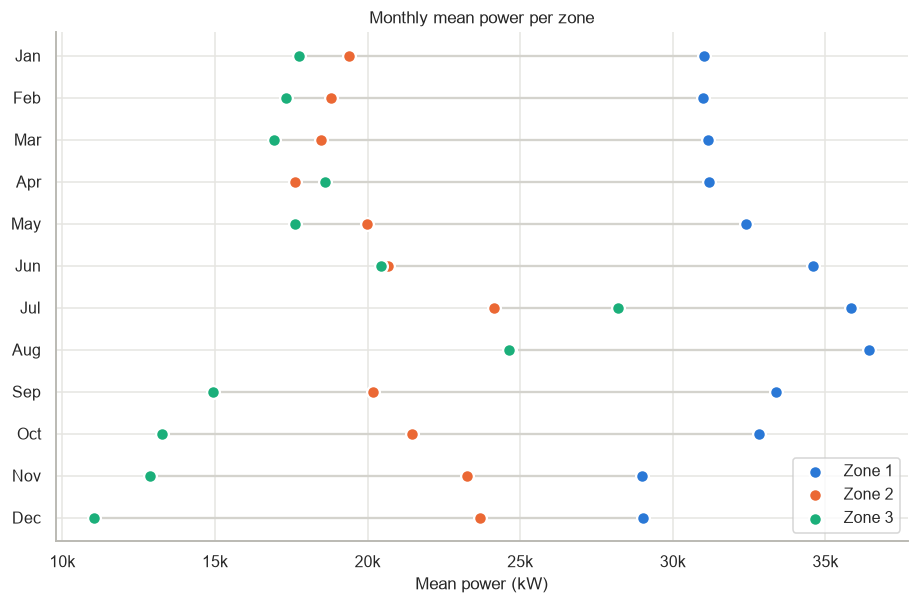

Zone 2 minus Zone 3 (kW) by month: {1: 1648, 2: 1453, 3: 1510, 4: -959, 5: 2355, 6: 240, 7: -4046, 8: 7, 9: 5256, 10: 8205, 11: 10377, 12: 12639}


In [14]:
mon = df.groupby('month')[ZONES].mean()
names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(10, 6))
for m in mon.index:
    ax.plot([mon.loc[m].min(), mon.loc[m].max()], [m, m], color='#d4d3cd', lw=1.5, zorder=1)
for z in ZONES:
    ax.scatter(mon[z], mon.index, s=70, color=ZONE_COLORS[z], edgecolor='white', linewidth=1.5, zorder=2, label=ZL[z])
ax.set_yticks(mon.index, names); ax.invert_yaxis(); ax.xaxis.set_major_formatter(fmt_k)
ax.set(title='Monthly mean power per zone', xlabel='Mean power (kW)')
ax.legend(loc='lower right')
save_fig('19_dot_plot_monthly_zone'); plt.show()

gap = mon.zone2 - mon.zone3
print('Zone 2 minus Zone 3 (kW) by month:', gap.round(0).astype(int).to_dict())

**Inferences:**
- Zone 1 is always far ahead (29k–36k kW); the interesting part is Zone 2 vs Zone 3.
- Zone 3 rises above Zone 2 in **April** (+1.0k) and **July** (+4.0k); in **August** they are equal (7 kW apart, so the dots overlap).
- From September the gap opens steadily to **12.6k kW in December** → Zones 2 and 3 have opposite seasonal patterns.

## 20 · Stem-and-leaf — weekly mean city load (52 weeks)
**Why stem-and-leaf here:** the summary set is small (52 values), so this display is nearly **lossless** — every weekly value stays readable (to 1,000 kW) while the shape of the distribution is still visible, unlike a histogram which hides values inside bins.
Split stems: `6L` holds leaves 0–4, `6H` holds 5–9. Key: `7L | 3` = 73,000 kW.

Weekly mean city load (thousand kW)   key: 7L | 3 = 73,000 kW

6L | 3 4 4 4 4
6H | 5 5 6 6 6 6 7 7 7 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8 8 9 9 9 9 9
7L | 0 0 1 1 3 4 4
7H | 6 9
8L | 1 4
8H | 7 8
9L | 0 0 1
9H | 5


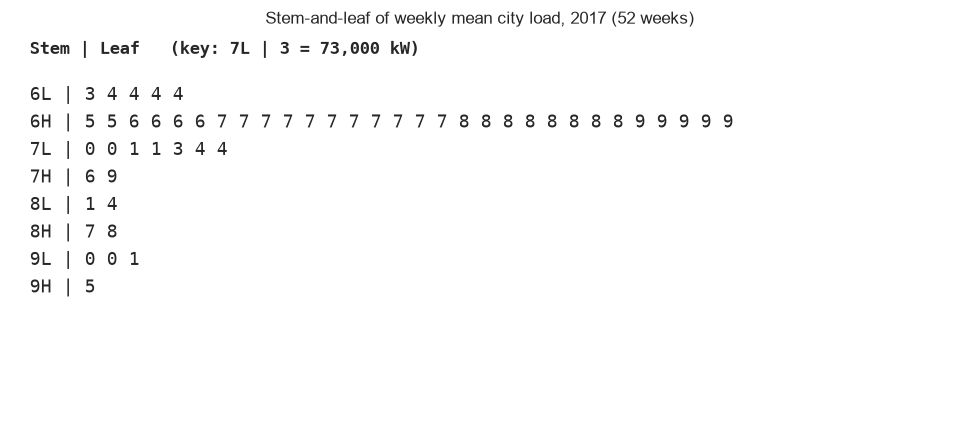


min 63k | Q1 67k | median 68k | Q3 72k | max 95k
Weeks >= 80k start on: ['02-Jul', '09-Jul', '16-Jul', '23-Jul', '30-Jul', '06-Aug', '13-Aug', '20-Aug']


In [15]:
day_idx = (df.date - df.date.min()).dt.days
weekly = (df.groupby(day_idx // 7).total_power.mean() / 1000).round().astype(int)   # 52 values, thousand kW
assert len(weekly) == 52

def stem_leaf(values):
    rows = {}
    for v in sorted(values):
        stem, leaf = divmod(v, 10)
        key = (stem, 'L' if leaf < 5 else 'H')
        rows.setdefault(key, []).append(str(leaf))
    lo, hi = min(rows)[0], max(rows)[0]
    lines = []
    for s in range(lo, hi + 1):
        for half in ('L', 'H'):
            lines.append(f"{s}{half} | {' '.join(rows.get((s, half), []))}")
    return lines

lines = stem_leaf(weekly.tolist())
print('Weekly mean city load (thousand kW)   key: 7L | 3 = 73,000 kW\n'); print('\n'.join(lines))

fig, ax = plt.subplots(figsize=(11, 0.42*len(lines) + 1.4))
ax.axis('off')
ax.text(0.02, 0.98, 'Stem | Leaf   (key: 7L | 3 = 73,000 kW)', family='monospace', fontsize=11,
        fontweight='bold', va='top', transform=ax.transAxes)
ax.text(0.02, 0.88, '\n'.join(lines), family='monospace', fontsize=12, va='top', linespacing=1.5, transform=ax.transAxes)
ax.set_title('Stem-and-leaf of weekly mean city load, 2017 (52 weeks)')
save_fig('20_stem_and_leaf_weekly_load'); plt.show()

print(f'\nmin {weekly.min()}k | Q1 {weekly.quantile(.25):.0f}k | median {weekly.median():.0f}k | Q3 {weekly.quantile(.75):.0f}k | max {weekly.max()}k')
print('Weeks >= 80k start on:', (df.date.min() + pd.to_timedelta(weekly[weekly >= 80].index*7, 'D')).strftime('%d-%b').tolist())

**Inferences:**
- 37 of 52 weeks fall in **63k–74k kW** (median 68k, Q1 67k, Q3 72k): a tight cluster → most of the year is stable.
- A clear **right tail**: all 8 weeks ≥ 80k kW start between **2 July and 20 August**; maximum 95k kW.
- With only 52 values, the stem-and-leaf shows this shape **and** keeps every weekly value readable (to 1,000 kW). A histogram would hide the values inside bins.

## Summary of key inferences

| # | Plot | Key inference |
|---|---|---|
| 07 | Histogram | Wind is two-regime; irradiance 48 % zeros + long tail; Zone 3 right-skewed |
| 08 | Box | Weekend drop: Zone 2 −9.5 %, Zone 1 −4.5 %, Zone 3 none |
| 09 | Violin | Ramadan shifts load: night +41 %, morning −11 % |
| 10 | Line | July–Aug peak; Zone 3 swings 2.55×; Eid dips visible |
| 11 | Stacked area | 06:50 trough → 20:10 peak, 2.0× daily swing |
| 12 | Scatter | r = 0.49 overall, 0.59 within the same hour; > 30 °C → +34 % load |
| 13 | Donut | 622 GWh; Zone 1 = 45 % |
| 14 | Grouped bar | Summer vs winter: Zone 3 +59 %, Zone 1 +18 %, Zone 2 +12 % |
| 15 | Pareto | 18–22 h ≈ 27 % of energy; no 80/20 — large base load |
| 16 | Radar | Zone 1 steady base, Zone 3 seasonal, Zone 2 weekday-driven |
| 17 | Heatmap | Peak hour follows sunset (18→20 h); Ramadan night block |
| 18 | Treemap | Summer = 29.6 % of energy; only season with Zone 3 > Zone 2 |
| 19 | Dot plot | Zones 2 & 3 cross in summer, then diverge to 12.6k kW |
| 20 | Stem-and-leaf | Stable 63–74k kW core; 8 summer weeks ≥ 80k kW |

**Implications for the next phases:** time of day, season, Ramadan and day type are the strongest structure in the data → they are the key ARM items (DIC, COFI), the KNN inputs (with temperature and solar), and the labels used to interpret DIANA day clusters.